In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import detector_model as dm

In [2]:
source = dm.Source()

rng = np.random.default_rng(2026)

directions = source.emit(E=1.0, rng=rng)

print(directions.shape)

assert directions.shape == (10_000, 3)

assert np.allclose(
    np.linalg.norm(directions, axis=1),
    1
)

print("Средние компоненты:", directions.mean(axis=0))

(10000, 3)
Средние компоненты: [-0.00425032 -0.00413056 -0.0056235 ]


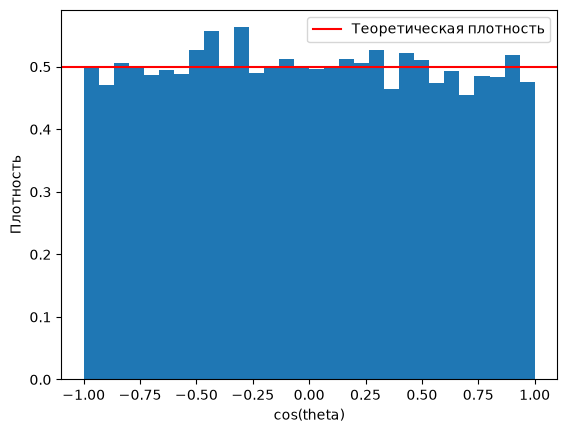

In [3]:
#Проверяем изотропность
plt.hist(
    directions[:, 2],
    bins=30,
    density=True
)

plt.axhline(
    0.5,
    color="red",
    label="Теоретическая плотность"
)

plt.xlabel("cos(theta)")
plt.ylabel("Плотность")
plt.legend()

plt.show()

In [4]:
#Проверяем линейность
for E in [0.2, 0.5, 1.0, 2.0]:
    directions = source.emit(E, rng)
    print(E, "МэВ:", len(directions), "фотонов")

0.2 МэВ: 2000 фотонов
0.5 МэВ: 5000 фотонов
1.0 МэВ: 10000 фотонов
2.0 МэВ: 20000 фотонов
